In [12]:
# Imports
import numpy as np
import os
import soundfile as sf 
import librosa
import matplotlib.pyplot as plt
import umap
import pandas as pd
import seaborn as sns

In [4]:
# Function that finds all files with a certain extension in a particular folder
def find_all_files(folders, ext, check_sub_folders=1):
    """Find all files with a .txt extension in all folders in folder list (and subfolders if check_sub_folders = 1 (default))"""
    all_files = []
    if isinstance(folders, str):
        # Make sure input is a list of folders
        folders = [folders]
    for f, folder in enumerate(folders):
        for subfolder in os.listdir(folder):

            if os.path.isdir(os.path.join(folder, subfolder)):
                if check_sub_folders:
                    folders.append(os.path.join(folder, subfolder))                
            elif subfolder.endswith(ext):
                all_files.append(os.path.join(folder,subfolder))
    return all_files

In [5]:
# Function that pads or cuts a spectrogram to a certain size, adapted from avgn
def pad_spectrogram(spectrogram, pad_length):
    """ Pads a spectrogram to being a certain length
    """
    excess_needed = pad_length - np.shape(spectrogram)[1]
    pad_left = np.floor(float(excess_needed) / 2).astype("int")
    pad_right = np.ceil(float(excess_needed) / 2).astype("int")
    if excess_needed >= 0:
        return np.pad(
            spectrogram, [(0, 0), (pad_left, pad_right)], "constant", constant_values=0
        )
    else:
        pad_left = np.floor(float(excess_needed) / 2).astype("int")
        pad_right = np.ceil(float(excess_needed) / 2).astype("int")
        return spectrogram[:,-1*pad_left:pad_right]

## Important variables
There are a few variables that will influence the outcome of especially spectral features. These are:
- fmin and fmax - the minimum and maximum frequency to consider when calculating variables. Usually used to cut off low-frequency and high-frequency noise. This needs to be adapted to the species, these values need to be higher when targeting USVs than audible vocalizations for example.
- spec_shape - this is the shape of the spectrogram for the latent feature analysis. You want this to be a multiple of 2. The optimal size depends on the samplerate of the recordings and the average length of the vocalizations
- nfft - when calculating a spectrogram, you typically take samples of nfft length and calculate the frequency spectrum in this smaller sample. You then slide this window across your recordings to get the frequencies at each time point. Ideally n_fft is a power of 2 (for faster computation), the optimum again depends on the samplerate and length of the vocalizations
- hop_length is the number of samples you slide the n_fft window. A smaller number results in a higher time resolution, but more smoothed result. 

In [6]:
# Constant variables
fmin = 1000
fmax = 10000 # Max frequency cutoff
spec_shape = [128, 128] #Shape of spectrogram
n_fft = 2048
hop_length = int(n_fft/2)


In [7]:
# Find all the audio files
data_folder = r"C:\Users\grijseels\Documents\Github\AnimalBehaviourLiveWorkshop\test_data"
data_files = find_all_files(data_folder, '.flac')

## Example call
We will first look at some features on a single audio fragment, a marmoset phee call. First, we need to load the call. Then we will plot the spectrogram using librosa to have an idea of what it looks like. We will plot the spectrogram with 3 different axes: mel-spaced, linear, and log, to show the difference for the latent feature extraction later. This is also a good point to check if our n_fft, hop_length, and frequency settings seem reasonable.

Next we'll calculate the fundamental frequency and the peak frequency. We'll look at how good it is at estimating this from the given audio fragment.

In [6]:
## Example data file
file = data_files[200]
data, sr = sf.read(file) # read in the file using soundfile

(1000.0, 10000.0)

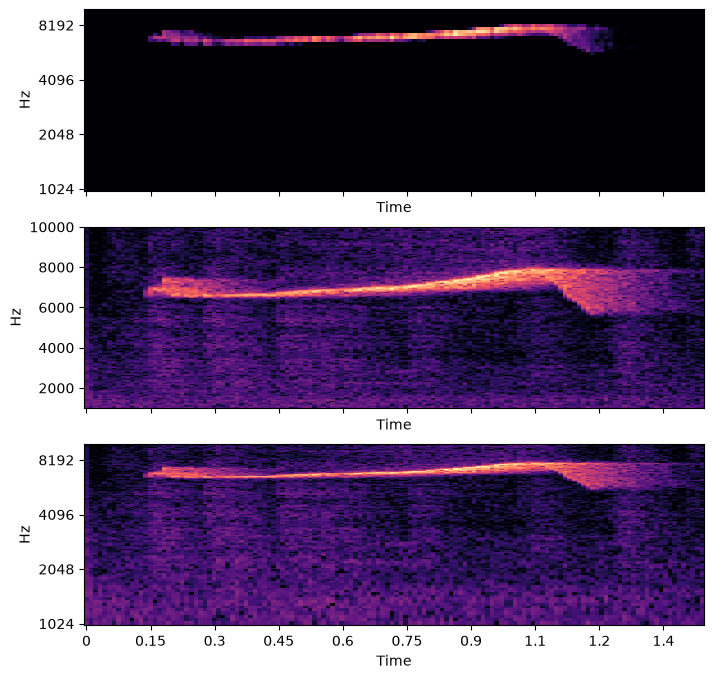

In [7]:
# Calculate a mel spectrogram of the data for better visualization
mel_spec = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, n_fft=n_fft, hop_length = hop_length)
# Compute an STFT
stft_spec = librosa.stft(y=data, n_fft=n_fft, hop_length = hop_length)

# Plot the spectograms and show the differences
fig, ax = plt.subplots(nrows=3, sharex=True, figsize=(8, 8))
mel_img = librosa.display.specshow(mel_spec, x_axis='time', y_axis='mel',vscale="dBFS",sr=sr, ax=ax[0],  n_fft=n_fft, hop_length = hop_length)
ax[0].set_ylim((fmin, fmax))
stft_img = librosa.display.specshow(stft_spec, x_axis='time', y_axis='hz',vscale="dBFS",sr=sr, ax=ax[1], n_fft=n_fft, hop_length = hop_length)
ax[1].set_ylim((fmin, fmax))
log_img = librosa.display.specshow(stft_spec, x_axis='time', y_axis='log',vscale="dBFS",sr=sr, ax=ax[2], n_fft=n_fft, hop_length = hop_length)
ax[2].set_ylim((fmin, fmax))




In [8]:
# Calculate the fundamental frequency and voiced (i.e. tonal) portion
f0, voiced_flag, voiced_probs = librosa.pyin(y=data, sr=sr, frame_length = n_fft, hop_length = hop_length,fmin=fmin, fmax=fmax)
   
# Calculate the peak frequency
spec =  np.abs(librosa.stft(y=data, n_fft = n_fft, hop_length = hop_length))
freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
spec_bp = spec[np.logical_and(freqs>1000, freqs<10000), :]
freqs_bp= freqs [np.logical_and(freqs>1000, freqs<10000)]
peak_freq = freqs_bp[np.argmax(spec_bp, 0)]

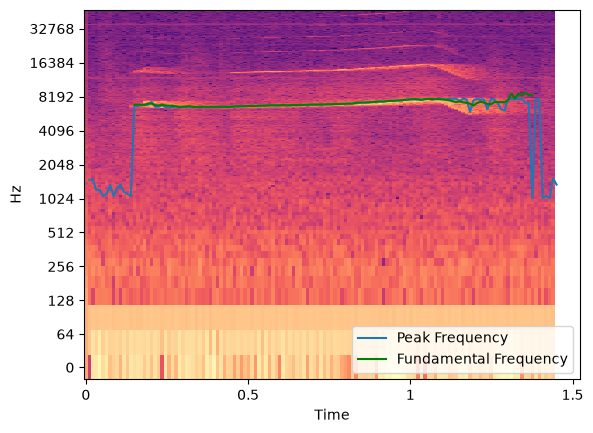

In [9]:
# Visualization
fig, ax = plt.subplots()
img = librosa.display.specshow(np.log(spec), y_axis='log', x_axis='time', sr = sr, ax=ax, n_fft = n_fft, hop_length = hop_length, fmin=fmin, fmax=fmax)
times = librosa.times_like(spec, sr=sr, n_fft = n_fft, hop_length = hop_length)
ax.plot(times, peak_freq, label='Peak Frequency')
ax.plot(times, f0, 'g', label='Fundamental Frequency')
ax.legend(loc='lower right')


### Also look at this call using parselmouth (PRAAT)

Text(0, 0.5, 'frequency [Hz]')

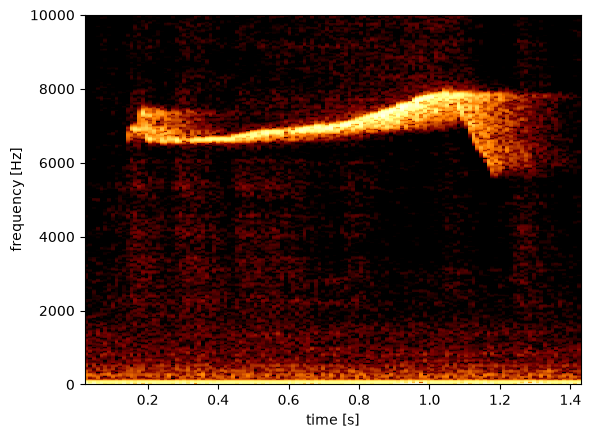

In [22]:
import parselmouth
snd = parselmouth.Sound(file)

spectrogram = snd.to_spectrogram(maximum_frequency=fmax, window_length = n_fft/sr, time_step=hop_length/sr)
plt.figure()
X, Y = spectrogram.x_grid(), spectrogram.y_grid()
sg_db = 10 * np.log10(spectrogram.values)
plt.pcolormesh(X, Y, sg_db, vmin=sg_db.max() - 70, cmap='afmhot')
plt.ylim([spectrogram.ymin, spectrogram.ymax])
plt.xlabel("time [s]")
plt.ylabel("frequency [Hz]")

## Feature extraction from all vocalizations
Now we can run through all the files and calculate the features for each vocalizations. We put this in a pandas dataframe for further use, where we'll also save the call type (extracted from the filename). 

In [28]:
features = []
for i, file in enumerate(data_files):
    data, sr = sf.read(file) 
    call_type = os.path.basename(file).split('_')[0]
    
    duration = len(data)/sr
    
    # spectral entropy
    mean_entropy = np.nanmean(librosa.feature.spectral_flatness(y=data, n_fft=n_fft, hop_length=hop_length))
    
    # Spectral bandwidth
    spectral_bw = np.nanmean(librosa.feature.spectral_bandwidth(y=data, sr=sr,n_fft=n_fft,  hop_length=hop_length))
    
    # Fundamental frequency and voiced (i.e. tonal) portion
    f0, voiced_flag, voiced_probs = librosa.pyin(data, sr=sr, frame_length = n_fft, hop_length = hop_length,fmin=fmin, fmax=fmax)
   
    # Peak frequency
    spec =  np.abs(librosa.stft(y=data, n_fft = n_fft, hop_length = hop_length))
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    # Bandpass the spectrogram and get the peak frequency
    spec_bp = spec[np.logical_and(freqs>fmin, freqs<fmax), :]
    freqs_bp= freqs [np.logical_and(freqs>fmin, freqs<fmax)]
    peak_freq = freqs_bp[np.argmax(spec_bp, 0)]

    # RMS (root mean square), a measure of loudness
    rms = np.nanmean(librosa.feature.rms(y=data))
    
    # Zero crossings
    zero_crossings = np.mean(librosa.zero_crossings(data, pad=False))


    features.append(pd.DataFrame.from_dict([{
        "call_type": call_type,
        "duration": duration,
        "f0": np.nanmean(f0),
        'pf': np.nanmean(peak_freq),
        "spectral_bw": spectral_bw,
        "mean_entropy": mean_entropy,
        'zero_crossings': zero_crossings
    }]))
features = pd.concat(features, ignore_index=True)
features.to_csv('test_data_features.csv') # Save out the features to csv 

C:\Users\grijseels\AppData\Local\Temp\ipykernel_26216\263652943.py:35: RuntimeWarning: Mean of empty slice
  "f0": np.nanmean(f0),


We can save out and reload the features to and from a csv file, which is also useful for exporting to other programs, e.g. GraphPad to do stats and make graphs. In this case it saves us from having to rerun the code above every time we look at the data.

In [11]:
features = pd.read_csv('test_data_features.csv', index_col=0) # Load from csv
features


,call_type,duration,f0,pf,spectral_bw,mean_entropy,zero_crossings
0,Infant,0.90,7047.144366,7842.463235,6114.803959,0.000320,0.067963
1,Infant,0.90,8383.819829,8114.889706,6007.167172,0.000238,0.039074
2,Infant,0.90,8487.072497,8165.625000,6283.892614,0.000209,0.044861
3,Infant,1.00,8304.549648,7871.010638,6282.813394,0.000169,0.030854
4,Infant,0.90,7231.097728,6645.772059,6091.815725,0.000392,0.046238
...,...,...,...,...,...,...,...
2015,Twitter,2.15,6500.175720,6313.041460,5616.426155,0.000132,0.036652
2016,Twitter,2.25,6302.203696,6113.744076,5476.289805,0.000122,0.038431
2017,Twitter,1.55,6518.219249,5108.411815,5673.116349,0.000044,0.011001
2018,Twitter,2.50,6213.207420,6110.106383,5378.276813,0.000095,0.041879


Let's visualize the correlation between the features first, this may show that some are superfluous.

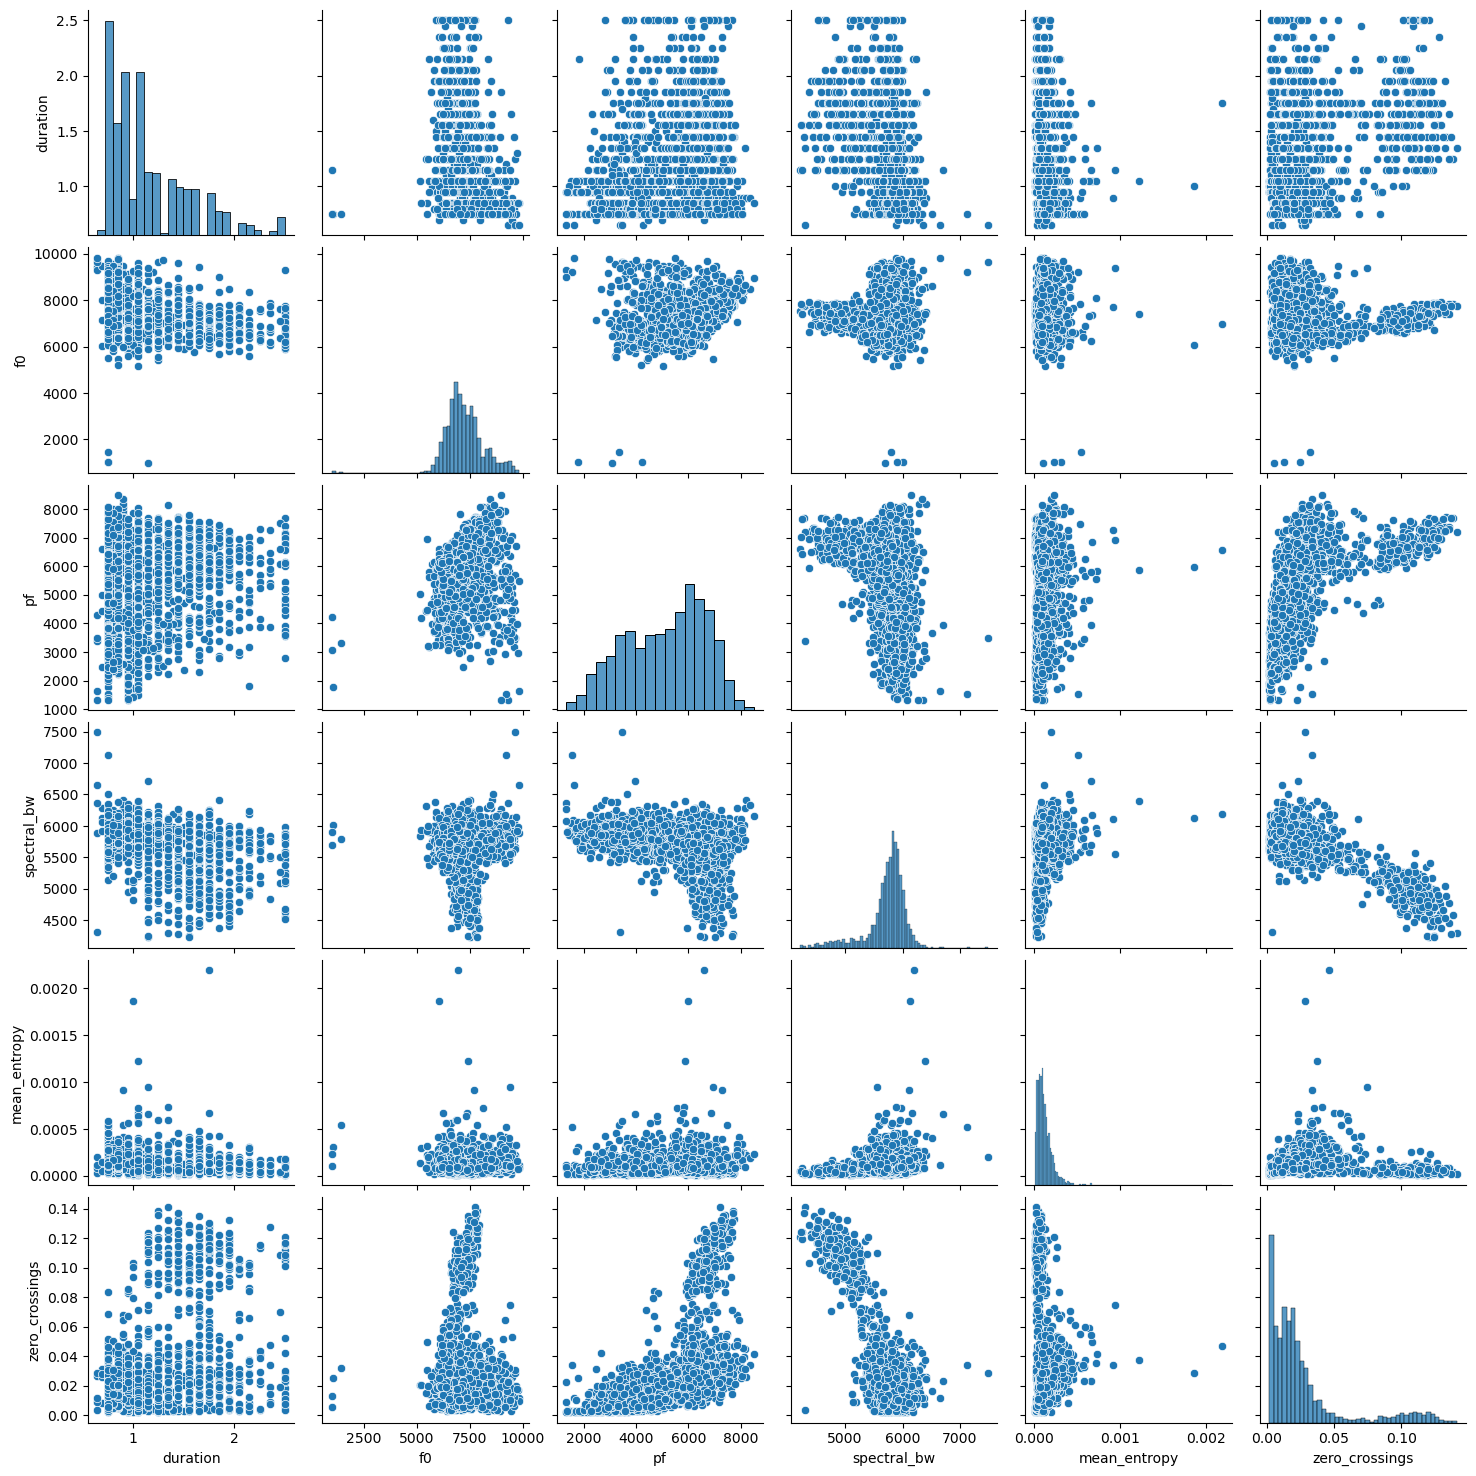

In [15]:
features_to_use = ['duration', 'f0', 'pf', 'spectral_bw', 'mean_entropy', 'zero_crossings']
sns.pairplot(features[features_to_use])

Now we can use dimensionality reduction to plot these features in a 2D space. To do this, we'll first extract the values from the pandas dataframe and put them into a numpy array. Then we'll run the data reduction methods. Here we'll focus on two, UMAP and PCA, though many more are available.

In [16]:
feature_array = features[features_to_use].values


TypeError: 'numpy.ndarray' object is not callable